# Dueling Network Architectures for Deep Reinforcement Learning

**Paper:** Wang, Z., Schaul, T., Hessel, M., van Hasselt, H., Lanctot, M., & de Freitas, N. (2016). *Dueling Network Architectures for Deep Reinforcement Learning.* ICML 2016. [arXiv:1511.06581](https://arxiv.org/abs/1511.06581)

This notebook implements a **standard DQN** and a **Dueling DQN** from scratch in PyTorch, trains both on CartPole-v1 with the same seed and settings, and compares their rewards and Q-values. The dueling architecture splits the Q-network into a **value stream** V(s) and an **advantage stream** A(s, a), then combines them:

Q(s, a) = V(s) + A(s, a) − mean_a' A(s, a')

The Summary at the end says what this run found.


## 1. Setup & Imports

In [1]:
import atexit
import os
import shutil
import subprocess
import sys

# Install gymnasium if needed
try:
    import gymnasium as gym
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "gymnasium", "-q"],
                          stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
    import gymnasium as gym

import random
import numpy as np
from collections import deque
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
from matplotlib_inline.backend_inline import set_matplotlib_formats

# Show figures as JPEG at a modest resolution to keep the saved notebook small
set_matplotlib_formats('jpeg')
plt.rcParams['figure.dpi'] = 80

# On Kaggle (detected from its environment), keep a copy of this notebook with its outputs when
# the kernel exits, so `kaggle kernels output` can download the executed version
if 'KAGGLE_KERNEL_RUN_TYPE' in os.environ:
    atexit.register(lambda: os.path.exists('__notebook__.ipynb')
                    and shutil.copy('__notebook__.ipynb', 'executed_solution.ipynb'))

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
# One CPU thread and deterministic kernels, so results do not depend on the machine's core count
torch.set_num_threads(1)
torch.use_deterministic_algorithms(True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")

Device: cpu


## 2. Hyperparameters

In [2]:
STATE_DIM = 4          # CartPole observation dimension
ACTION_DIM = 2         # CartPole actions (left, right)
HIDDEN_DIM = 128       # Hidden layer size
LR = 1e-3              # Learning rate
GAMMA = 0.99           # Discount factor
BUFFER_SIZE = 10_000   # Replay buffer capacity
BATCH_SIZE = 64        # Minibatch size
TARGET_UPDATE_FREQ = 10  # Episodes between target network updates
EPS_START = 1.0        # Initial epsilon
EPS_END = 0.05         # Final epsilon
EPS_DECAY = 0.995      # Epsilon decay per episode
NUM_EPISODES = 300     # Training episodes
MAX_STEPS = 500        # Max steps per episode

## 3. Environment Setup

In [3]:
env = gym.make("CartPole-v1")
print(f"Observation space: {env.observation_space}")
print(f"Action space: {env.action_space}")

# Run a random episode
state, _ = env.reset(seed=SEED)
env.action_space.seed(SEED)
for step in range(50):
    action = env.action_space.sample()
    state, reward, terminated, truncated, _ = env.step(action)
    if terminated or truncated:
        break
env.close()
print(f"Random episode lasted {step+1} steps")

Observation space: Box([-4.8               -inf -0.41887903        -inf], [4.8               inf 0.41887903        inf], (4,), float32)
Action space: Discrete(2)
Random episode lasted 30 steps


## 4. Standard DQN Network

A simple MLP that outputs a Q-value for each action directly.


In [4]:
class DQNetwork(nn.Module):
    """Standard DQN: directly outputs Q(s, a) for all actions."""
    def __init__(self, state_dim, action_dim, hidden_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(state_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, action_dim)
        )

    def forward(self, x):
        return self.net(x)  # (batch, action_dim)

## 5. Dueling DQN Network

The core contribution: after shared feature layers, the network splits into a **value stream** and an **advantage stream**, then combines them:

Q(s, a) = V(s) + A(s, a) − mean_a' A(s, a')

Subtracting the mean advantage (rather than the max) is the version the paper uses in its experiments. The paper notes it loses the original meaning of V and A, since both are now off by a constant, but makes optimization more stable.


In [5]:
class DuelingDQNetwork(nn.Module):
    """Dueling DQN: splits into value V(s) and advantage A(s,a) streams."""
    def __init__(self, state_dim, action_dim, hidden_dim):
        super().__init__()
        # Shared feature layers
        self.shared = nn.Sequential(
            nn.Linear(state_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU()
        )
        # Value stream: outputs single V(s)
        self.value_stream = nn.Linear(hidden_dim, 1)
        # Advantage stream: outputs A(s, a) for each action
        self.advantage_stream = nn.Linear(hidden_dim, action_dim)

    def forward(self, x):
        features = self.shared(x)                   # (batch, hidden_dim)
        value = self.value_stream(features)          # (batch, 1)
        advantage = self.advantage_stream(features)  # (batch, action_dim)
        # Mean aggregation: Q(s,a) = V(s) + A(s,a) - mean(A)
        q_values = value + advantage - advantage.mean(dim=1, keepdim=True)
        return q_values  # (batch, action_dim)

    def get_value_advantage(self, x):
        """Extract V(s) and A(s,a) separately for visualization."""
        features = self.shared(x)
        value = self.value_stream(features)
        advantage = self.advantage_stream(features)
        return value, advantage


for name, cls in [('Standard DQN', DQNetwork), ('Dueling DQN', DuelingDQNetwork)]:
    n_params = sum(p.numel() for p in cls(STATE_DIM, ACTION_DIM, HIDDEN_DIM).parameters())
    print(f'{name} parameters: {n_params:,}')


Standard DQN parameters: 17,410
Dueling DQN parameters: 17,539


## 6. Experience Replay Buffer

In [6]:
class ReplayBuffer:
    """Stores transitions and samples random minibatches."""
    def __init__(self, capacity):
        self.buffer = deque(maxlen=capacity)

    def push(self, state, action, reward, next_state, done):
        self.buffer.append((state, action, reward, next_state, done))

    def sample(self, batch_size):
        batch = random.sample(self.buffer, batch_size)
        states, actions, rewards, next_states, dones = zip(*batch)
        return (
            torch.FloatTensor(np.array(states)),
            torch.LongTensor(actions),
            torch.FloatTensor(rewards),
            torch.FloatTensor(np.array(next_states)),
            torch.FloatTensor(dones)
        )

    def __len__(self):
        return len(self.buffer)

## 7. ε-Greedy Action Selection

In [7]:
def select_action(state, policy_net, epsilon, action_dim):
    """ε-greedy: random with prob ε, else argmax Q."""
    if random.random() < epsilon:
        return random.randrange(action_dim)
    with torch.no_grad():
        state_t = torch.FloatTensor(state).unsqueeze(0).to(device)
        q_values = policy_net(state_t)
        return q_values.argmax(dim=1).item()

## 8. Optimization Step

In [8]:
def optimize_step(policy_net, target_net, buffer, optimizer, batch_size, gamma):
    """Standard DQN optimization — works with either network architecture."""
    if len(buffer) < batch_size:
        return 0.0, 0.0

    states, actions, rewards, next_states, dones = buffer.sample(batch_size)
    states = states.to(device)
    actions = actions.to(device)
    rewards = rewards.to(device)
    next_states = next_states.to(device)
    dones = dones.to(device)

    # Current Q-values for taken actions
    current_q = policy_net(states).gather(1, actions.unsqueeze(1)).squeeze(1)

    # Target: r + γ * max_a' Q(s', a'; θ⁻)
    with torch.no_grad():
        next_q = target_net(next_states).max(dim=1)[0]
        target_q = rewards + gamma * next_q * (1 - dones)

    loss = nn.functional.smooth_l1_loss(current_q, target_q)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    return loss.item(), current_q.mean().item()

## 9. Training Loop

In [9]:
def train_agent(network_class, env, num_episodes=NUM_EPISODES, seed=SEED):
    """Train a DQN or Dueling DQN agent and return training metrics."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    policy_net = network_class(STATE_DIM, ACTION_DIM, HIDDEN_DIM).to(device)
    target_net = network_class(STATE_DIM, ACTION_DIM, HIDDEN_DIM).to(device)
    target_net.load_state_dict(policy_net.state_dict())
    target_net.eval()

    optimizer = optim.Adam(policy_net.parameters(), lr=LR)
    buffer = ReplayBuffer(BUFFER_SIZE)
    epsilon = EPS_START

    episode_rewards = []
    episode_losses = []
    mean_q_values = []

    for episode in range(num_episodes):
        state, _ = env.reset(seed=seed + episode)
        total_reward = 0
        ep_loss = 0
        ep_q = 0
        steps = 0

        for step in range(MAX_STEPS):
            action = select_action(state, policy_net, epsilon, ACTION_DIM)
            next_state, reward, terminated, truncated, _ = env.step(action)
            done = terminated or truncated
            buffer.push(state, action, reward, next_state, float(done))
            state = next_state
            total_reward += reward
            steps += 1

            loss, q_val = optimize_step(
                policy_net, target_net, buffer, optimizer, BATCH_SIZE, GAMMA
            )
            ep_loss += loss
            ep_q += q_val

            if done:
                break

        # Update target network
        if (episode + 1) % TARGET_UPDATE_FREQ == 0:
            target_net.load_state_dict(policy_net.state_dict())

        epsilon = max(EPS_END, epsilon * EPS_DECAY)

        episode_rewards.append(total_reward)
        episode_losses.append(ep_loss / max(steps, 1))
        mean_q_values.append(ep_q / max(steps, 1))

        if (episode + 1) % 50 == 0:
            avg_reward = np.mean(episode_rewards[-50:])
            print(f"  Episode {episode+1:3d} | Avg reward (last 50): {avg_reward:.1f} | ε: {epsilon:.3f}")

    return policy_net, episode_rewards, episode_losses, mean_q_values

## 10. Train Standard DQN

In [10]:
print("Training Standard DQN...")
env_train = gym.make("CartPole-v1")
dqn_net, dqn_rewards, dqn_losses, dqn_q_values = train_agent(
    DQNetwork, env_train, num_episodes=NUM_EPISODES
)
env_train.close()
print("Standard DQN training complete.")

Training Standard DQN...


  Episode  50 | Avg reward (last 50): 23.8 | ε: 0.778


  Episode 100 | Avg reward (last 50): 34.8 | ε: 0.606


  Episode 150 | Avg reward (last 50): 65.0 | ε: 0.471


  Episode 200 | Avg reward (last 50): 53.4 | ε: 0.367


  Episode 250 | Avg reward (last 50): 63.7 | ε: 0.286


  Episode 300 | Avg reward (last 50): 126.0 | ε: 0.222
Standard DQN training complete.


## 11. Train Dueling DQN

In [11]:
print("Training Dueling DQN...")
env_train2 = gym.make("CartPole-v1")
dueling_net, dueling_rewards, dueling_losses, dueling_q_values = train_agent(
    DuelingDQNetwork, env_train2, num_episodes=NUM_EPISODES
)
env_train2.close()
print("Dueling DQN training complete.")

Training Dueling DQN...


  Episode  50 | Avg reward (last 50): 22.4 | ε: 0.778


  Episode 100 | Avg reward (last 50): 36.7 | ε: 0.606


  Episode 150 | Avg reward (last 50): 46.4 | ε: 0.471


  Episode 200 | Avg reward (last 50): 89.1 | ε: 0.367


  Episode 250 | Avg reward (last 50): 72.9 | ε: 0.286


  Episode 300 | Avg reward (last 50): 143.6 | ε: 0.222
Dueling DQN training complete.


## 12. Comparison Plots

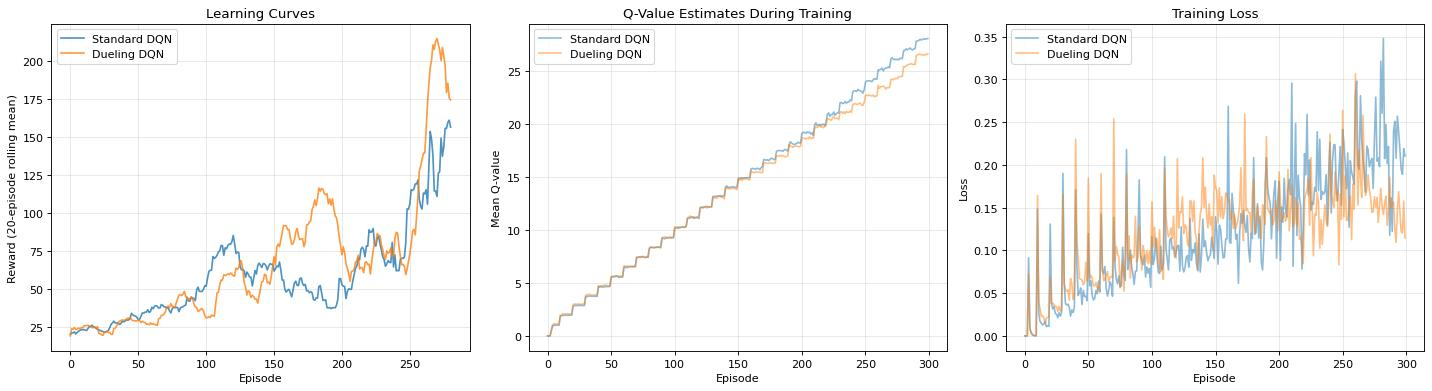

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Reward curves
ax = axes[0]
window = 20
dqn_smoothed = np.convolve(dqn_rewards, np.ones(window)/window, mode='valid')
dueling_smoothed = np.convolve(dueling_rewards, np.ones(window)/window, mode='valid')
ax.plot(dqn_smoothed, label='Standard DQN', alpha=0.8)
ax.plot(dueling_smoothed, label='Dueling DQN', alpha=0.8)
ax.set_xlabel('Episode')
ax.set_ylabel('Reward (20-episode rolling mean)')
ax.set_title('Learning Curves')
ax.legend()
ax.grid(True, alpha=0.3)

# Q-value estimates
ax = axes[1]
ax.plot(dqn_q_values, label='Standard DQN', alpha=0.5)
ax.plot(dueling_q_values, label='Dueling DQN', alpha=0.5)
ax.set_xlabel('Episode')
ax.set_ylabel('Mean Q-value')
ax.set_title('Q-Value Estimates During Training')
ax.legend()
ax.grid(True, alpha=0.3)

# Loss curves
ax = axes[2]
ax.plot(dqn_losses, label='Standard DQN', alpha=0.5)
ax.plot(dueling_losses, label='Dueling DQN', alpha=0.5)
ax.set_xlabel('Episode')
ax.set_ylabel('Loss')
ax.set_title('Training Loss')
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('training_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

## 13. Evaluation: Greedy Policy

Standard DQN  — Greedy eval: 500.0 ± 0.0 (max: 500)
Dueling DQN   — Greedy eval: 207.8 ± 28.6 (max: 225)


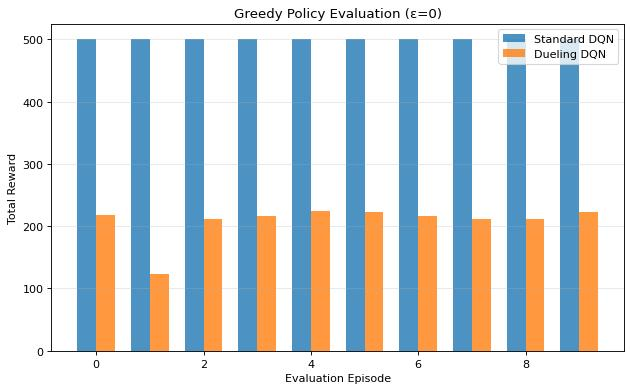

In [13]:
def evaluate(policy_net, env, num_episodes=10):
    """Run greedy policy (ε=0) and return average reward."""
    rewards = []
    for ep in range(num_episodes):
        state, _ = env.reset(seed=1000 + ep)
        total_reward = 0
        for step in range(MAX_STEPS):
            action = select_action(state, policy_net, 0.0, ACTION_DIM)
            state, reward, terminated, truncated, _ = env.step(action)
            total_reward += reward
            if terminated or truncated:
                break
        rewards.append(total_reward)
    return rewards

env_eval = gym.make("CartPole-v1")
dqn_eval = evaluate(dqn_net, env_eval)
dueling_eval = evaluate(dueling_net, env_eval)
env_eval.close()

print(f"Standard DQN  — Greedy eval: {np.mean(dqn_eval):.1f} ± {np.std(dqn_eval):.1f} (max: {np.max(dqn_eval):.0f})")
print(f"Dueling DQN   — Greedy eval: {np.mean(dueling_eval):.1f} ± {np.std(dueling_eval):.1f} (max: {np.max(dueling_eval):.0f})")

fig, ax = plt.subplots(figsize=(8, 5))
x = np.arange(len(dqn_eval))
width = 0.35
ax.bar(x - width/2, dqn_eval, width, label='Standard DQN', alpha=0.8)
ax.bar(x + width/2, dueling_eval, width, label='Dueling DQN', alpha=0.8)
ax.set_xlabel('Evaluation Episode')
ax.set_ylabel('Total Reward')
ax.set_title('Greedy Policy Evaluation (ε=0)')
ax.legend()
ax.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.savefig('evaluation_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

## 14. Value and Advantage Visualization

For the dueling network, we extract V(s) and A(s, a) separately for 100 sampled states to see how it splits its Q-values.


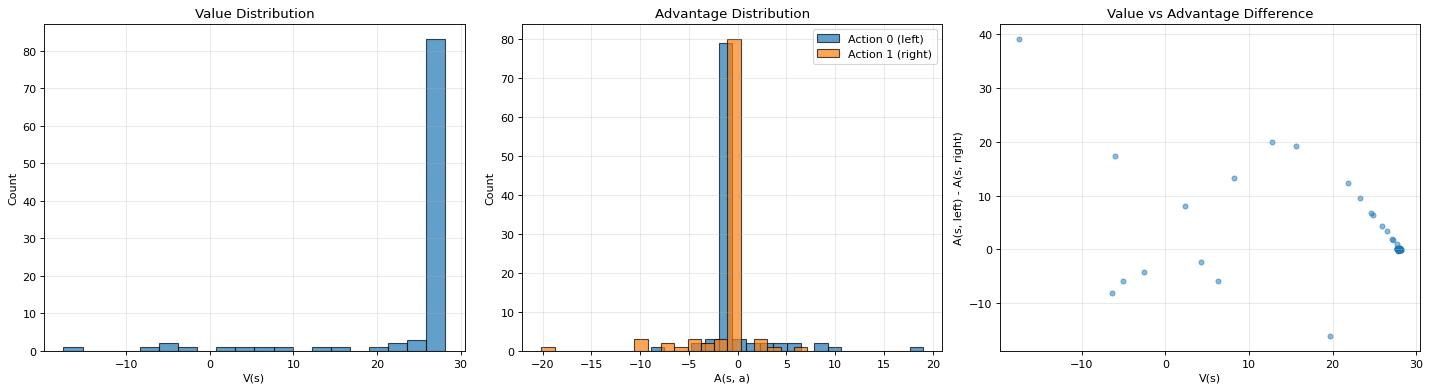


Value stats:     mean=24.66, std=8.91
Advantage (left):  mean=-0.16, std=3.00
Advantage (right): mean=-1.40, std=2.90
Mean |A(s, left) - A(s, right)|: 2.11


In [14]:
# Sample some states from the environment
env_viz = gym.make("CartPole-v1")
sample_states = []
env_viz.action_space.seed(SEED)
viz_rng = random.Random(SEED)
for i in range(100):
    state, _ = env_viz.reset(seed=5000 + i)
    for _ in range(viz_rng.randint(0, 50)):
        action = env_viz.action_space.sample()
        state, reward, terminated, truncated, _ = env_viz.step(action)
        sample_states.append(state)
        if terminated or truncated:
            break
env_viz.close()

sample_states = np.array(sample_states[:100])
states_t = torch.FloatTensor(sample_states).to(device)

with torch.no_grad():
    values, advantages = dueling_net.get_value_advantage(states_t)

values_np = values.cpu().numpy().flatten()
advantages_np = advantages.cpu().numpy()
q_values = dueling_net(states_t).detach().cpu().numpy()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

ax = axes[0]
ax.hist(values_np, bins=20, edgecolor='black', alpha=0.7)
ax.set_xlabel('V(s)')
ax.set_ylabel('Count')
ax.set_title('Value Distribution')
ax.grid(True, alpha=0.3)

ax = axes[1]
ax.hist(advantages_np[:, 0], bins=20, alpha=0.7, label='Action 0 (left)', edgecolor='black')
ax.hist(advantages_np[:, 1], bins=20, alpha=0.7, label='Action 1 (right)', edgecolor='black')
ax.set_xlabel('A(s, a)')
ax.set_ylabel('Count')
ax.set_title('Advantage Distribution')
ax.legend()
ax.grid(True, alpha=0.3)

ax = axes[2]
ax.scatter(values_np, advantages_np[:, 0] - advantages_np[:, 1], alpha=0.5, s=20)
ax.set_xlabel('V(s)')
ax.set_ylabel('A(s, left) - A(s, right)')
ax.set_title('Value vs Advantage Difference')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('value_advantage_decomposition.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"\nValue stats:     mean={values_np.mean():.2f}, std={values_np.std():.2f}")
print(f"Advantage (left):  mean={advantages_np[:, 0].mean():.2f}, std={advantages_np[:, 0].std():.2f}")
print(f"Advantage (right): mean={advantages_np[:, 1].mean():.2f}, std={advantages_np[:, 1].std():.2f}")
print(f"Mean |A(s, left) - A(s, right)|: {np.abs(advantages_np[:, 0] - advantages_np[:, 1]).mean():.2f}")

## 15. Learning Speed Comparison

In [15]:
# Episodes to reach reward threshold
threshold = 475  # CartPole-v1 "solved" threshold

def episodes_to_threshold(rewards, threshold, window=10):
    """Find first episode where rolling mean exceeds threshold."""
    for i in range(window, len(rewards)):
        if np.mean(rewards[i-window:i]) >= threshold:
            return i
    return len(rewards)

dqn_ep = episodes_to_threshold(dqn_rewards, threshold)
dueling_ep = episodes_to_threshold(dueling_rewards, threshold)

print(f"Episodes to reach {threshold}+ reward (10-episode rolling mean):")
print(f"  Standard DQN:  {dqn_ep if dqn_ep < NUM_EPISODES else 'Not reached'}")
print(f"  Dueling DQN:   {dueling_ep if dueling_ep < NUM_EPISODES else 'Not reached'}")
print(f"\nFinal 50-episode average reward:")
print(f"  Standard DQN:  {np.mean(dqn_rewards[-50:]):.1f}")
print(f"  Dueling DQN:   {np.mean(dueling_rewards[-50:]):.1f}")

Episodes to reach 475+ reward (10-episode rolling mean):
  Standard DQN:  Not reached
  Dueling DQN:   Not reached

Final 50-episode average reward:
  Standard DQN:  126.0
  Dueling DQN:   143.6


## 16. Summary

### What the run above shows

- **Neither network was clearly better.** Over the last 50 training episodes, the dueling network averaged **143.6** against the standard DQN's **126.0**. But in the 10-episode greedy evaluation, the standard DQN reached the 500-step cap every time (**500.0**), while the dueling network averaged **207.8**. Neither reached a 10-episode rolling average of 475 during training.
- **The Q-value curves were almost the same.** Both rose steadily through training, with the standard DQN's ending slightly higher. The run shows no sign that the dueling network's estimates were more stable.
- **The value and advantage streams separated as designed.** For 100 sample states, V(s) averaged **24.66** while the advantages averaged **−0.16** (left) and **−1.40** (right), with a mean gap of **2.11** between the two actions. The value stream carries most of each Q-value.
- **The networks are nearly the same size:** 17,410 parameters for the standard DQN and 17,539 for the dueling one.
- **One seed, and results depend on the run.** Before the notebook pinned PyTorch to one CPU thread, two earlier Kaggle runs of the same code (not saved here) gave opposite outcomes: one had the dueling network far ahead (186.8 vs 82.5 in training, 475.4 vs 183.8 greedy), the other had it behind (76.4 vs 82.9, 93.4 vs 111.9). CartPole has only two actions, where the paper reports the smallest benefit; testing the paper's claim would need many seeds and harder tasks.
